In [3]:
%pip -q install "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "koreanize-matplotlib==0.1.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


구리 곡선 VQE 선택 비트: [0 1 1 1 1 0]
기대 QUBO 비용: 0.004540661899700094
선택 목적값 / 완전탐색 최솟값 / 차이: 0.0019175170068029823 0.0019175170068029823 0.0
선택 상태 확률: 0.5023732858771008
회귀 계수: [0.5 1.  0. ]
격자 VQE MSE / 연속 최소제곱 MSE: 0.001917517006802724 0.0006549791271672586


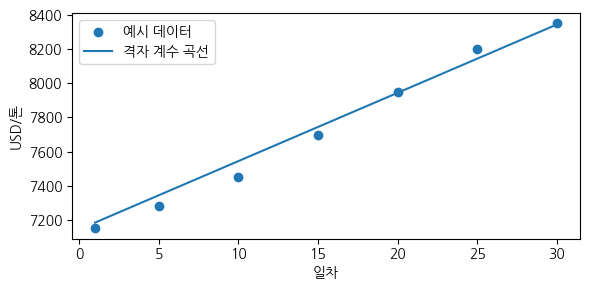

   1일 | 관측  7150.00 | 근사  7184.29 | 오차   +34.29
   5일 | 관측  7280.00 | 근사  7344.29 | 오차   +64.29
  10일 | 관측  7450.00 | 근사  7544.29 | 오차   +94.29
  15일 | 관측  7700.00 | 근사  7744.29 | 오차   +44.29
  20일 | 관측  7950.00 | 근사  7944.29 | 오차    -5.71
  25일 | 관측  8200.00 | 근사  8144.29 | 오차   -55.71
  30일 | 관측  8350.00 | 근사  8344.29 | 오차    -5.71
MAE (USD/톤): 43.46938775510249
RMSE (USD/톤): 52.54735473642755


/tmp/ipykernel_2017/3782653888.py:112: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) NanumGothic.
  plt.tight_layout(); plt.show(); plt.close()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) NanumGothic.
  fig.canvas.print_figure(bytes_io, **kw)


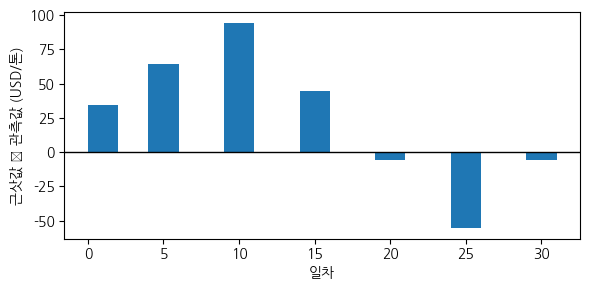

18일차 곡선 근삿값: 7864.29 USD/톤


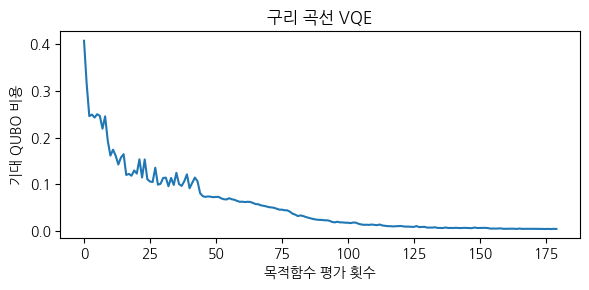

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib
from itertools import product
from qiskit.circuit.library import real_amplitudes
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import Statevector
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo

# 1. 입력 데이터
days = np.array([1, 5, 10, 15, 20, 25, 30])
price = np.array([7150, 7280, 7450, 7700, 7950, 8200, 8350])

# 2. 날짜와 가격 정규화
x_center, x_scale = days.mean(), days.max()
y_min, y_range = price.min(), float(np.ptp(price))
x = (days-x_center)/x_scale
y = (price-y_min)/y_range

# 3. 계수 비트와 MSE 목적함수
phi = np.column_stack([np.ones(len(x)), x, x*x])
base = np.array([0.0, -0.5, -0.5])
step = np.array([0.25, 0.5, 0.5])
B = np.zeros((3, 6))
for j in range(3):
    B[j, 2*j:2*j+2] = step[j] * np.array([1, 2])
A = phi @ B
r = phi @ base-y
problem = QuadraticProgram()
for j in range(6):
    problem.binary_var(f'b{j}')
problem.minimize(constant=float(r@r/len(y)),
                 linear=2*A.T@r/len(y), quadratic=A.T@A/len(y))

# 4. QUBO와 Ising 해밀토니안
converter = QuadraticProgramToQubo()
qubo = converter.convert(problem)
H, offset = qubo.to_ising()
n = qubo.get_num_vars()
# 모든 기저상태에서 QUBO 목적값과 Ising 에너지의 대응을 확인합니다.
diagonal = np.real(np.diag(H.to_matrix())) + offset
for i, value in enumerate(diagonal):
    bits = np.array([(i >> j) & 1 for j in range(n)])
    assert np.isclose(value, qubo.objective.evaluate(bits))
# 5. 안자츠와 고전 최적화기
ansatz = real_amplitudes(n, reps=2, entanglement='linear')
history = []
vqe = VQE(StatevectorEstimator(), ansatz, COBYLA(maxiter=180),
          initial_point=np.array([0.5479120971119267, -0.12224312049589536, 0.7171958398227649, 0.3947360581187278, -0.8116453042247009, 0.9512447032735118, 0.5222794039807059, 0.5721286105539076, -0.7437727346489083, -0.09922812420886573, -0.25840395153483753, 0.8535299776972036, 0.2877302401613291, 0.64552322654166, -0.11317160234533774, -0.5455225564304462, 0.1091695740316696, -0.8723654877916494])[:ansatz.num_parameters],
          callback=lambda k, p, value, meta: history.append(float(value)+offset))
# 6. VQE 실행과 상태 확률 계산
result = vqe.compute_minimum_eigenvalue(H)
probabilities = Statevector.from_instruction(
    ansatz.assign_parameters(result.optimal_parameters)).probabilities()
# 7. 선택 복원과 정확 최솟값 검증
# 실행 가능한 상태 중 확률이 가장 큰 상태를 선택합니다.
candidates = []
for i, p in enumerate(probabilities):
    bits = np.array([(i >> j) & 1 for j in range(n)])
    original_bits = np.asarray(converter.interpret(bits))
    if problem.is_feasible(original_bits):
        candidates.append((float(p), original_bits))
probability, chosen = max(candidates, key=lambda item: item[0])
value = float(problem.objective.evaluate(chosen))
exact = min(
    float(problem.objective.evaluate(np.asarray(bits)))
    for bits in product((0, 1), repeat=problem.get_num_vars())
    if problem.is_feasible(np.asarray(bits))
)
print("구리 곡선 VQE", '선택 비트:', chosen.astype(int))
print('기대 QUBO 비용:', float(result.eigenvalue.real)+offset)
print('선택 목적값 / 완전탐색 최솟값 / 차이:', value, exact, value-exact)
print('선택 상태 확률:', probability)

coeff = base + B @ chosen
prediction = phi @ coeff
mse = np.mean((prediction - y) ** 2)
assert np.isclose(problem.objective.evaluate(chosen), mse)
classical = np.linalg.lstsq(phi, y, rcond=None)[0]
print('회귀 계수:', coeff)
print('격자 VQE MSE / 연속 최소제곱 MSE:',
      mse, np.mean((phi @ classical - y) ** 2))

# 8. 업무 결과 출력과 저장
np.savez('copper_model.npz', coeff=coeff, center=x_center, scale=x_scale,
         y_min=y_min, y_range=y_range)
plt.figure(figsize=(6, 3)); plt.scatter(days, price, label='예시 데이터')
grid = np.linspace(1, 30, 100); u = (grid-x_center)/x_scale
plt.plot(grid, y_min+y_range*(coeff[0]+coeff[1]*u+coeff[2]*u*u), label='격자 계수 곡선')
plt.xlabel('일차'); plt.ylabel('USD/톤'); plt.legend(); plt.tight_layout()
plt.savefig('copper_fit.png'); plt.show(); plt.close()

# 저장한 모델을 불러와 예측값과 오차를 계산합니다.
with np.load('copper_model.npz') as model:
    observed_days = np.array([1, 5, 10, 15, 20, 25, 30], dtype=float)
    observed_prices = np.array([7150, 7280, 7450, 7700, 7950, 8200, 8350], dtype=float)
    u = (observed_days-model['center'])/model['scale']
    a = model['coeff']
    fitted = model['y_min']+model['y_range']*(a[0]+a[1]*u+a[2]*u*u)
    errors = fitted-observed_prices
    for day, actual, estimate, error in zip(observed_days, observed_prices, fitted, errors):
        print(f'{day:4.0f}일 | 관측 {actual:8.2f} | 근사 {estimate:8.2f} | 오차 {error:+8.2f}')
    print('MAE (USD/톤):', np.mean(np.abs(errors)))
    print('RMSE (USD/톤):', np.sqrt(np.mean(errors**2)))
    plt.figure(figsize=(6, 3))
    plt.bar(observed_days, errors, width=2)
    plt.axhline(0, color='black', linewidth=1)
    plt.xlabel('일차'); plt.ylabel('근삿값 − 관측값 (USD/톤)')
    plt.tight_layout(); plt.show(); plt.close()

with np.load('copper_model.npz') as m:
    day = 18.0
    u = (day-m['center'])/m['scale']
    a = m['coeff']
    price = float(m['y_min']+m['y_range']*(a[0]+a[1]*u+a[2]*u*u))
    print(f'{day:g}일차 곡선 근삿값: {price:.2f} USD/톤')

title = "구리 곡선 VQE"
plt.figure(figsize=(6, 3)); plt.plot(history)
plt.title(title); plt.xlabel('목적함수 평가 횟수'); plt.ylabel('기대 QUBO 비용')
plt.tight_layout(); plt.savefig(title+'.png', dpi=120); plt.show(); plt.close()